# Tugas 2 Pengolahan Citra Digital
## Segmentasi Citra dengan Metode Thresholding

**Nama:** Gibran Wicaksono  
**NIM:** 24260037

### Tujuan
Membuktikan bahwa metode thresholding dapat mengubah citra grayscale yang memiliki banyak tingkat intensitas menjadi citra biner yang hanya memiliki nilai hitam (0) dan putih (255).

In [9]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image, ImageOps
from pathlib import Path
from IPython.display import display
from tkinter import Tk, filedialog

print("Library berhasil disiapkan.")

Library berhasil disiapkan.


Foto berhasil dimuat: makan.jpeg


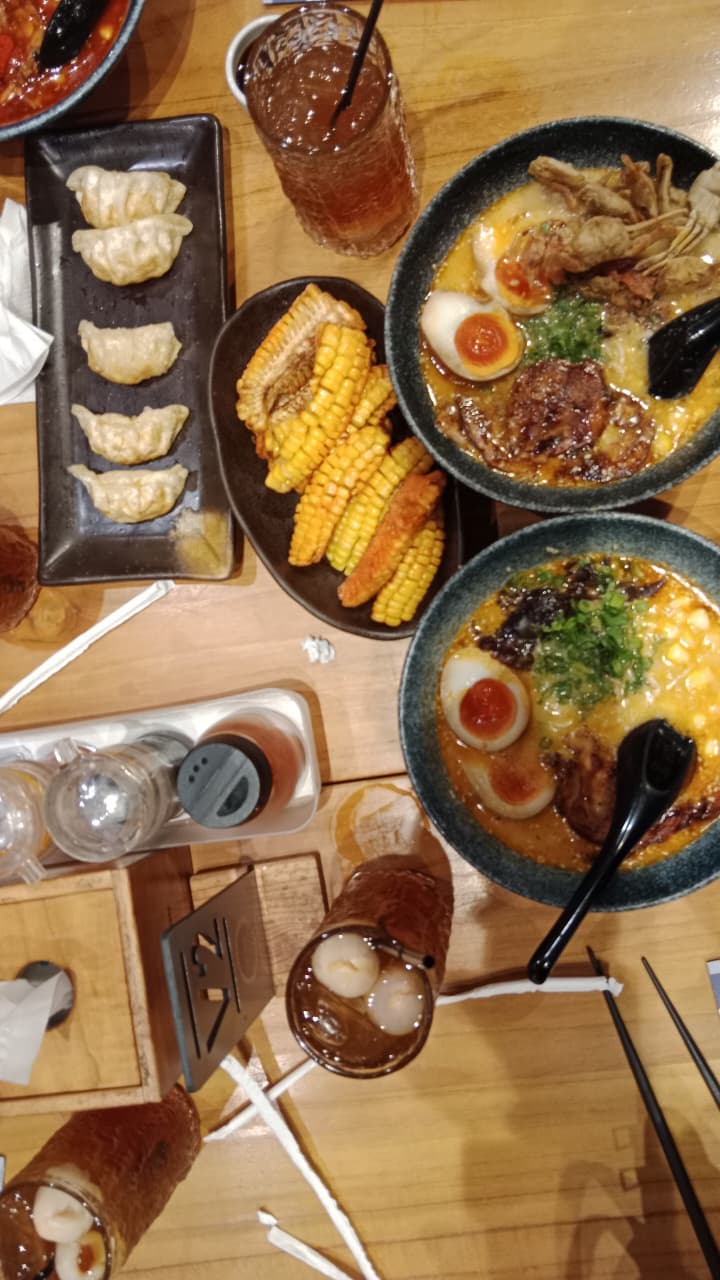

In [12]:
root = Tk()
root.withdraw()
root.attributes("-topmost", True)

file_foto = filedialog.askopenfilename(
    title="Pilih foto untuk thresholding",
    filetypes=[
        ("File gambar", "*.jpg *.jpeg *.png *.bmp")
    ]
)

root.destroy()

if file_foto:
    gambar_asli = Image.open(file_foto)
    print("Foto berhasil dimuat:", Path(file_foto).name)
    display(gambar_asli)
else:
    print("Foto belum dipilih.")

Dimensi citra: (1280, 720)
Tipe data: uint8
Jumlah piksel: 921600
Nilai intensitas minimum: 0
Nilai intensitas maksimum: 255
Jumlah tingkat intensitas yang ditemukan: 256


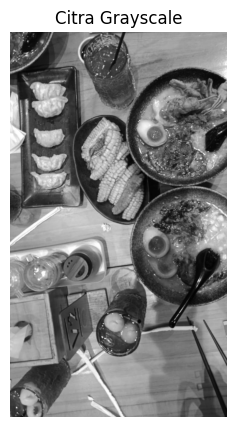

In [13]:
gambar_gray = ImageOps.grayscale(gambar_asli)
array_gray = np.array(gambar_gray)

print("Dimensi citra:", array_gray.shape)
print("Tipe data:", array_gray.dtype)
print("Jumlah piksel:", array_gray.size)
print("Nilai intensitas minimum:", array_gray.min())
print("Nilai intensitas maksimum:", array_gray.max())
print("Jumlah tingkat intensitas yang ditemukan:",
      len(np.unique(array_gray)))

plt.figure(figsize=(6, 5))
plt.imshow(array_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Grayscale")
plt.axis("off")
plt.show()

Threshold: 128
Nilai intensitas citra biner: [  0 255]
Jumlah tingkat intensitas citra biner: 2


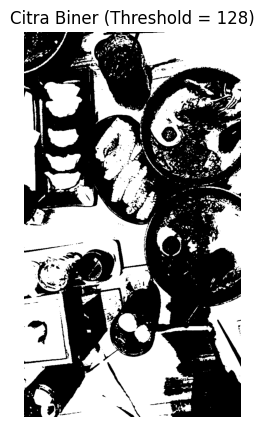

In [14]:
T = 128

array_biner = np.where(
    array_gray >= T,
    255,
    0
).astype(np.uint8)

gambar_biner = Image.fromarray(array_biner)

print("Threshold:", T)
print("Nilai intensitas citra biner:",
      np.unique(array_biner))
print("Jumlah tingkat intensitas citra biner:",
      len(np.unique(array_biner)))

plt.figure(figsize=(6, 5))
plt.imshow(array_biner, cmap="gray", vmin=0, vmax=255)
plt.title(f"Citra Biner (Threshold = {T})")
plt.axis("off")
plt.show()

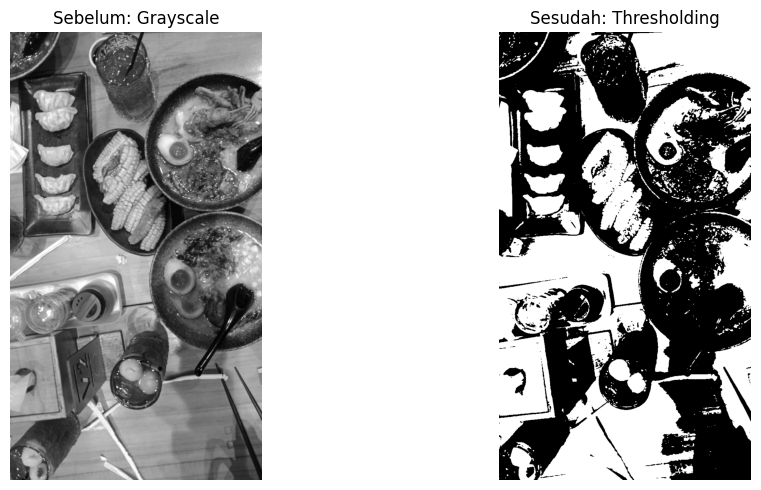

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(12, 5))

ax[0].imshow(array_gray, cmap="gray", vmin=0, vmax=255)
ax[0].set_title("Sebelum: Grayscale")
ax[0].axis("off")

ax[1].imshow(array_biner, cmap="gray", vmin=0, vmax=255)
ax[1].set_title("Sesudah: Thresholding")
ax[1].axis("off")

plt.tight_layout()
plt.show()

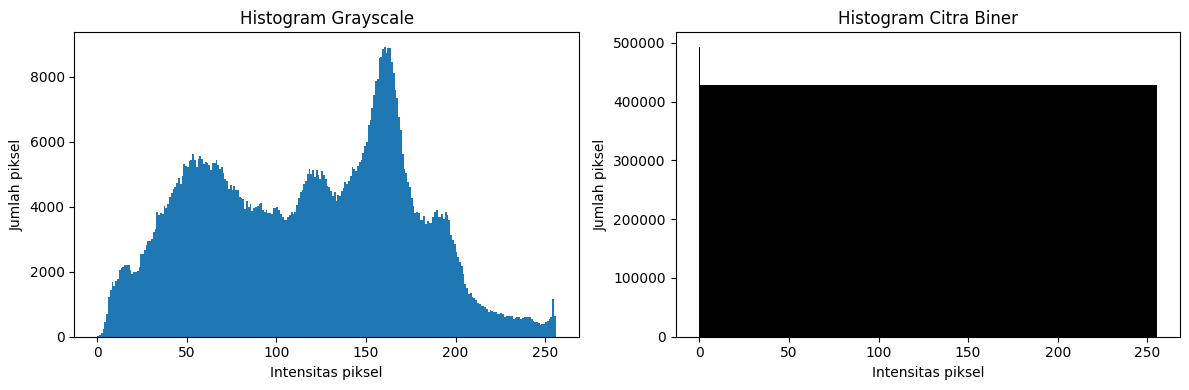

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

ax[0].hist(array_gray.ravel(), bins=256, range=(0, 256))
ax[0].set_title("Histogram Grayscale")
ax[0].set_xlabel("Intensitas piksel")
ax[0].set_ylabel("Jumlah piksel")

ax[1].hist(
    array_biner.ravel(),
    bins=[-0.5, 0.5, 255.5],
    color="black"
)
ax[1].set_title("Histogram Citra Biner")
ax[1].set_xlabel("Intensitas piksel")
ax[1].set_ylabel("Jumlah piksel")

plt.tight_layout()
plt.show()

In [17]:
folder_hasil = Path("hasil_thresholding")
folder_hasil.mkdir(exist_ok=True)

gambar_gray.save(folder_hasil / "citra_grayscale.png")
gambar_biner.save(folder_hasil / "citra_biner.png")

print("Hasil berhasil disimpan di:", folder_hasil.resolve())

Hasil berhasil disimpan di: C:\PCD2\hasil_thresholding


## Kesimpulan

Berdasarkan percobaan, metode thresholding dapat mengubah citra grayscale menjadi citra biner dengan menentukan nilai ambang sebesar 128. Piksel yang memiliki intensitas kurang dari 128 diubah menjadi hitam (0), sedangkan piksel yang memiliki intensitas sama dengan atau lebih dari 128 diubah menjadi putih (255).

Citra grayscale dapat memiliki hingga 256 tingkat intensitas, sedangkan citra biner hanya menggunakan maksimal dua tingkat intensitas. Perubahan ini menunjukkan bahwa thresholding dapat menyederhanakan informasi intensitas dan membantu memisahkan objek dari latar belakang.